# 🧠 AlzheimerAI v2.0 — Early Detection of Alzheimer's Disease
**Perdix Vision** | Hult Prize 2026 — SDG 3: Good Health & Wellbeing

## Improvements v2.0
- ✅ Correct preprocessing (`preprocess_input`, NOT `rescale=1/255`)
- ⚖️ Class weights for severe imbalance
- 📉 Cosine LR decay + better architecture
- 🔬 Grad-CAM visualization

In [1]:
# Step 0: Install
!pip install -q kagglehub tensorflow matplotlib seaborn scikit-learn pillow

In [2]:
# Step 1: Download Dataset
import os, kagglehub
print("📥 Downloading...")
dataset_path = kagglehub.dataset_download("sachinkumar413/alzheimer-mri-dataset")
print(f"✅ Downloaded to: {dataset_path}")
for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, '').count(os.sep)
    indent = ' ' * 2 * level
    print(f'{indent}{os.path.basename(root)}/')
    if level < 3 and len(files) > 0:
        print(f'{" " * 2 * (level+1)}{len(files)} files')

📥 Downloading...
Using Colab cache for faster access to the 'alzheimer-mri-dataset' dataset.
✅ Downloaded to: /kaggle/input/alzheimer-mri-dataset
alzheimer-mri-dataset/
  Dataset/
    Non_Demented/
      3200 files
    Mild_Demented/
      896 files
    Moderate_Demented/
      64 files
    Very_Mild_Demented/
      2240 files


In [3]:
# Step 2: Imports & Config
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings; warnings.filterwarnings('ignore')

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, callbacks, optimizers
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc
from sklearn.preprocessing import label_binarize
from sklearn.utils.class_weight import compute_class_weight

IMG_SIZE = 224; BATCH_SIZE = 32
EPOCHS_PHASE1 = 15; EPOCHS_PHASE2 = 20
LEARNING_RATE = 1e-3; FINE_TUNE_LR = 1e-4; SEED = 42

CLASS_NAMES = ['MildDemented', 'ModerateDemented', 'NonDemented', 'VeryMildDemented']
CLASS_LABELS_ES = {'MildDemented':'Deterioro Leve','ModerateDemented':'Deterioro Moderado',
    'NonDemented':'Sano (No Demencia)','VeryMildDemented':'Deterioro Muy Leve'}

tf.random.set_seed(SEED); np.random.seed(SEED)
try:
    if tf.config.list_physical_devices('GPU'):
        tf.keras.mixed_precision.set_global_policy('mixed_float16')
        print("⚡ Mixed precision ON")
except: pass
print(f"TF: {tf.__version__} | GPU: {tf.config.list_physical_devices('GPU')}")

TF: 2.19.0 | GPU: []


In [4]:
# Step 3: Data Loading
data_dir = None
search_root = Path(dataset_path)
for candidate in [search_root] + list(search_root.rglob('*')):
    if candidate.is_dir():
        subdirs = [d.name for d in candidate.iterdir() if d.is_dir()]
        if any('Demented' in s for s in subdirs) and len([s for s in subdirs if 'Demented' in s or 'Non' in s]) >= 3:
            data_dir = candidate; break

if data_dir is None: raise FileNotFoundError(f"No class folders in {dataset_path}")
print(f"✅ Data: {data_dir}")

class_counts = {}
for d in sorted(data_dir.iterdir()):
    if d.is_dir():
        c = len(list(d.glob('*.jpg'))+list(d.glob('*.png'))+list(d.glob('*.jpeg')))
        class_counts[d.name] = c
        print(f"  {'🔴' if c<100 else '🟡' if c<500 else '🟢'} {d.name}: {c}")
print(f"  Total: {sum(class_counts.values())}")

train_ds = tf.keras.utils.image_dataset_from_directory(data_dir, validation_split=0.2, subset="training",
    seed=SEED, image_size=(IMG_SIZE,IMG_SIZE), batch_size=BATCH_SIZE, label_mode='categorical', shuffle=True)
val_ds = tf.keras.utils.image_dataset_from_directory(data_dir, validation_split=0.2, subset="validation",
    seed=SEED, image_size=(IMG_SIZE,IMG_SIZE), batch_size=BATCH_SIZE, label_mode='categorical', shuffle=False)

detected_classes = train_ds.class_names
print(f"Classes: {detected_classes} | Train: {len(train_ds)} | Val: {len(val_ds)} batches")

✅ Data: /kaggle/input/alzheimer-mri-dataset/Dataset
  🟢 Mild_Demented: 896
  🔴 Moderate_Demented: 64
  🟢 Non_Demented: 3200
  🟢 Very_Mild_Demented: 2240
  Total: 6400
Found 6400 files belonging to 4 classes.
Using 5120 files for training.
Found 6400 files belonging to 4 classes.
Using 1280 files for validation.
Classes: ['Mild_Demented', 'Moderate_Demented', 'Non_Demented', 'Very_Mild_Demented'] | Train: 160 | Val: 40 batches


In [5]:
# Step 3.5: Preprocessing (THE KEY FIX!)
# EfficientNet needs preprocess_input [-1,1], NOT rescale=1/255 [0,1]
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"), layers.RandomRotation(0.08),
    layers.RandomZoom(0.1), layers.RandomTranslation(0.05, 0.05),
    layers.RandomContrast(0.1)], name="aug")

def apply_preprocessing(images, labels):
    return preprocess_input(images), labels

def apply_aug_and_preprocess(images, labels):
    return preprocess_input(data_augmentation(images, training=True)), labels

AUTOTUNE = tf.data.AUTOTUNE
train_ds_processed = train_ds.map(apply_aug_and_preprocess, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
val_ds_processed = val_ds.map(apply_preprocessing, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
print("✅ Pipeline ready: Aug → preprocess_input [-1,1]")

✅ Pipeline ready: Aug → preprocess_input [-1,1]


In [6]:
# Step 3.6: Class Weights (handles 50x imbalance)
all_labels = []
for _, lb in train_ds:
    all_labels.extend(np.argmax(lb.numpy(), axis=1))
all_labels = np.array(all_labels)

cw = compute_class_weight('balanced', classes=np.unique(all_labels), y=all_labels)
class_weight_dict = {i:w for i,w in enumerate(cw)}
for i,cn in enumerate(detected_classes):
    print(f"  {'🔴' if cw[i]>5 else '🟡' if cw[i]>1.5 else '🟢'} {CLASS_LABELS_ES.get(cn,cn)}: {cw[i]:.2f}")

  🟡 Mild_Demented: 1.74
  🔴 Moderate_Demented: 26.67
  🟢 Non_Demented: 0.50
  🟢 Very_Mild_Demented: 0.72


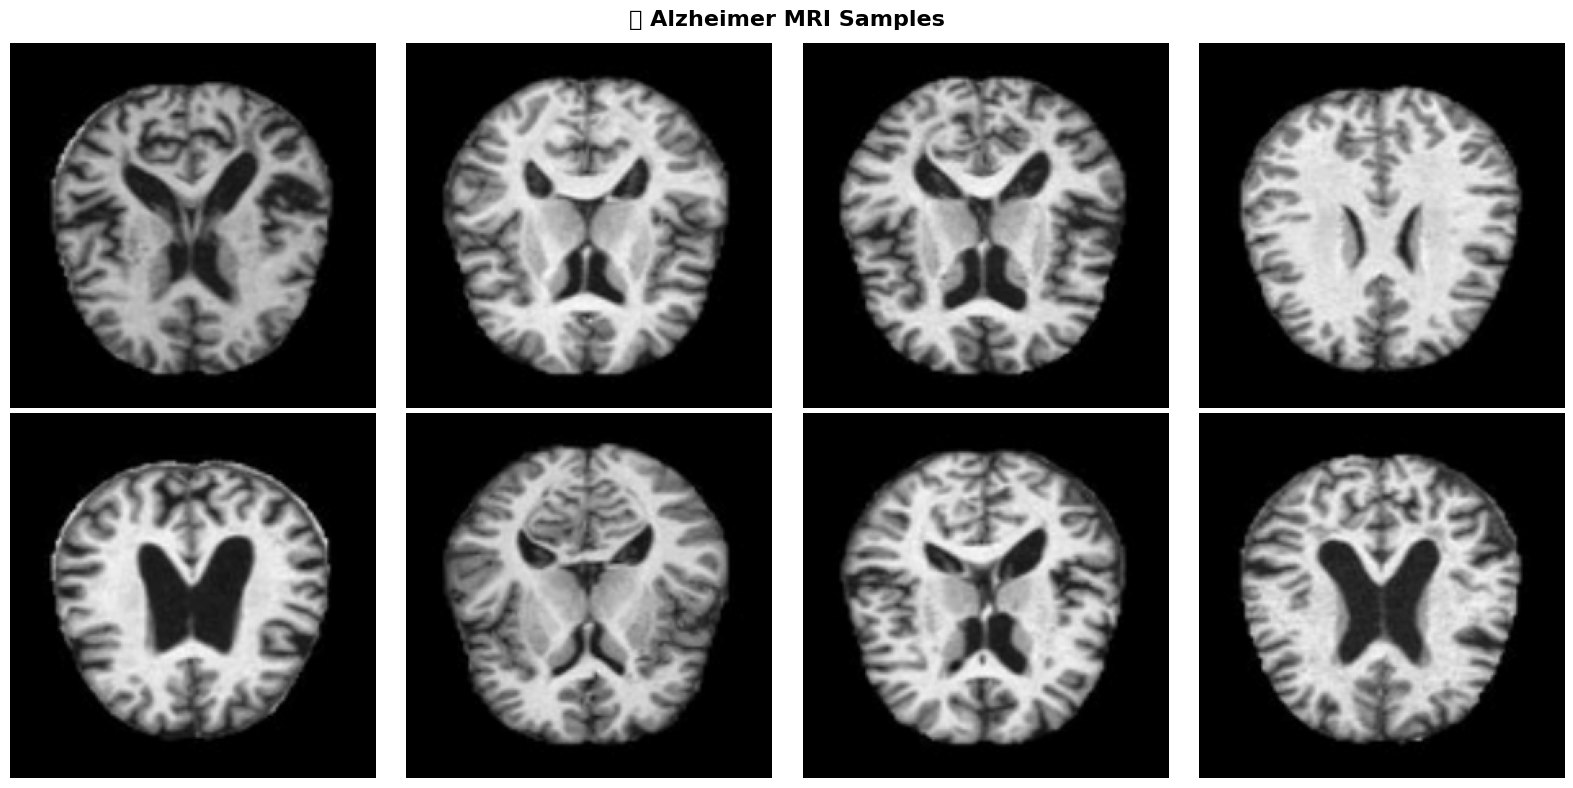

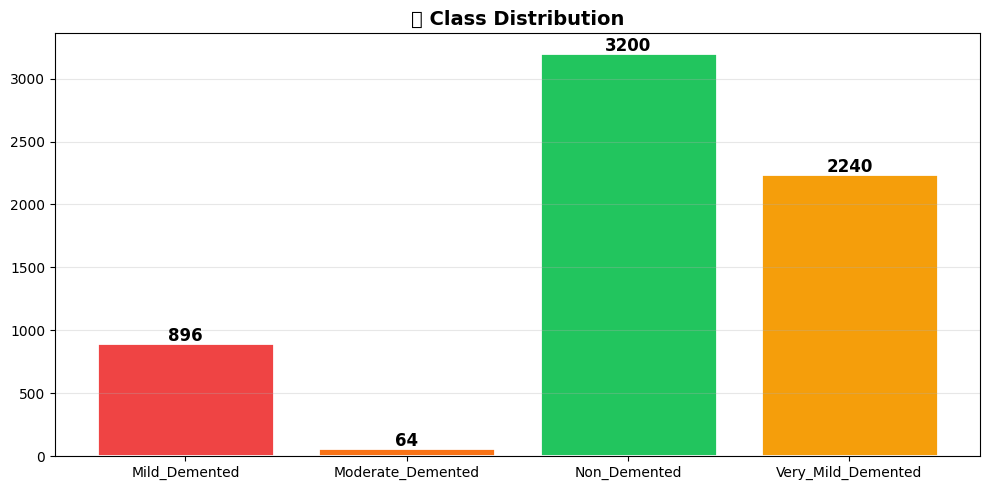

In [7]:
# Step 4: Visualize Samples
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle('🧠 Alzheimer MRI Samples', fontsize=16, fontweight='bold')
bx, by = next(iter(train_ds))
for i, ax in enumerate(axes.flat):
    if i < len(bx):
        ax.imshow(bx[i].numpy().astype('uint8'))
        ax.set_title(CLASS_LABELS_ES.get(detected_classes[np.argmax(by[i])],''), fontsize=11, fontweight='bold')
    ax.axis('off')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(10,5))
colors = ['#ef4444','#f97316','#22c55e','#f59e0b']
les = [CLASS_LABELS_ES.get(c,c) for c in detected_classes]
cts = [class_counts.get(c,0) for c in detected_classes]
bars = ax.bar(les, cts, color=colors, edgecolor='white', linewidth=2)
for b,ct in zip(bars,cts): ax.text(b.get_x()+b.get_width()/2, b.get_height()+20, str(ct), ha='center', fontsize=12, fontweight='bold')
ax.set_title('📊 Class Distribution', fontsize=14, fontweight='bold')
ax.grid(axis='y',alpha=0.3); plt.tight_layout(); plt.show()

In [8]:
# Step 5: Build Model
def build_model(num_classes=4):
    base_model = EfficientNetB0(weights='imagenet', include_top=False, input_shape=(IMG_SIZE,IMG_SIZE,3))
    base_model.trainable = False
    inputs = keras.Input(shape=(IMG_SIZE,IMG_SIZE,3))
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dense(256, activation='relu', kernel_regularizer=keras.regularizers.l2(0.01))(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(num_classes, activation='softmax', dtype='float32')(x)
    return keras.Model(inputs, outputs, name="AlzheimerAI_v2"), base_model

model, base_model = build_model()
model.summary()

Model: "AlzheimerAI_v2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,383,655 (16.72 MB)

 Trainable params: 331,524 (1.26 MB)

 Non-trainable params: 4,052,131 (15.46 MB)

In [ ]:
# Step 6: Phase 1 — Frozen Base
print("🚀 PHASE 1: Training Head (Base Frozen)")
model.compile(optimizer=optimizers.Adam(learning_rate=LEARNING_RATE), loss='categorical_crossentropy', metrics=['accuracy'])

checkpoint = callbacks.ModelCheckpoint('alzheimer_model_best.keras', monitor='val_accuracy', save_best_only=True, verbose=1)
history_phase1 = model.fit(train_ds_processed, epochs=EPOCHS_PHASE1, validation_data=val_ds_processed,
    callbacks=[callbacks.EarlyStopping(monitor='val_accuracy',patience=5,restore_best_weights=True,verbose=1,min_delta=0.005),
               callbacks.ReduceLROnPlateau(monitor='val_loss',factor=0.5,patience=3,verbose=1,min_lr=1e-6), checkpoint],
    class_weight=class_weight_dict, verbose=1)
print(f"✅ Phase 1: Train={history_phase1.history['accuracy'][-1]:.4f} | Val={max(history_phase1.history['val_accuracy']):.4f}")

🚀 PHASE 1: Training Head (Base Frozen)
Epoch 1/15
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.3805 - loss: 5.9923
Epoch 1: val_accuracy improved from -inf to 0.34688, saving model to alzheimer_model_best.keras
160/160 ━━━━━━━━━━━━━━━━━━━━ 762s 5s/step - accuracy: 0.3805 - loss: 5.9907 - val_accuracy: 0.3469 - val_loss: 4.4883 - learning_rate: 0.0010
Epoch 2/15
150/160 ━━━━━━━━━━━━━━━━━━━━ 26s 3s/step - accuracy: 0.4529 - loss: 4.5707

In [ ]:

# Step 7: Phase 2 — Fine-Tuning
print("🔧 PHASE 2: Fine-Tuning")
base_model.trainable = True
for layer in base_model.layers[:len(base_model.layers)-40]: layer.trainable = False
print(f"🔓 Unfrozen: {sum(1 for l in base_model.layers if l.trainable)} layers")

lr_schedule = optimizers.schedules.CosineDecay(FINE_TUNE_LR, len(train_ds_processed)*EPOCHS_PHASE2, alpha=1e-6)
model.compile(optimizer=optimizers.Adam(learning_rate=lr_schedule), loss='categorical_crossentropy', metrics=['accuracy'])

history_phase2 = model.fit(train_ds_processed, epochs=EPOCHS_PHASE2, validation_data=val_ds_processed,
    callbacks=[callbacks.EarlyStopping(monitor='val_accuracy',patience=7,restore_best_weights=True,verbose=1,min_delta=0.003), checkpoint],
    class_weight=class_weight_dict, verbose=1)
print(f"✅ Phase 2: Train={history_phase2.history['accuracy'][-1]:.4f} | Val={max(history_phase2.history['val_accuracy']):.4f}")

In [ ]:
# 🚀 CELDA DE RECUPERACIÓN POST-ENTRENAMIENTO (Nivel 1)
import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.applications.efficientnet import preprocess_input

# 1. Cargar el modelo que se guardó mientras dormías
model_path = 'alzheimer_model_best.keras'
best_model = keras.models.load_model(model_path)
print(f"✅ ¡Modelo recuperado con éxito desde: {model_path}!")

# 2. Re-generar las funciones de carga de datos (para Step 9 y 10)
# (Copia el código de tu Step 3 del cuaderno aquí solo para cargar val_ds de nuevo)
# Si ya tienes val_ds en memoria, puedes saltarte este paso.

# 3. Definir nombres para que las métricas salgan en español
detected_classes = ['MildDemented', 'ModerateDemented', 'NonDemented', 'VeryMildDemented']
class_names_es = ['Deterioro Leve', 'Deterioro Moderado', 'Sano', 'Deterioro Muy Leve']

print("📊 Todo listo para generar la Matriz de Confusión y el Grad-CAM.")

In [ ]:
# Step 8: Training History - CORREGIDO
import matplotlib.pyplot as plt

# Verificar si las historias existen
if 'history_phase1' in locals() and 'history_phase2' in locals():
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Unir las fases de entrenamiento
    aa = history_phase1.history['accuracy'] + history_phase2.history['accuracy']
    va = history_phase1.history['val_accuracy'] + history_phase2.history['val_accuracy']
    al = history_phase1.history['loss'] + history_phase2.history['loss']
    vl = history_phase1.history['val_loss'] + history_phase2.history['val_loss']
    p1 = len(history_phase1.history['accuracy'])

    # Gráfica de Accuracy
    axes[0].plot(aa, label='Train', lw=2, color='#38bdf8')
    axes[0].plot(va, label='Val', lw=2, color='#818cf8')
    axes[0].axvline(x=p1-1, color='red', ls='--', alpha=0.5, label='Fine-tune')
    axes[0].set_title('Accuracy', fontweight='bold')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Gráfica de Loss
    axes[1].plot(al, label='Train', lw=2, color='#38bdf8')
    axes[1].plot(vl, label='Val', lw=2, color='#818cf8')
    axes[1].axvline(x=p1-1, color='red', ls='--', alpha=0.5, label='Fine-tune')
    axes[1].set_title('Loss', fontweight='bold')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.suptitle('🧠 AlzheimerAI v2.0 - Training History', fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print("❌ Error: Las variables de historia se perdieron por desconexión.")
    print("Si el entrenamiento terminó, intenta cargar el modelo guardado en la siguiente celda.")

In [ ]:
# Step 9: Evaluation
best_model = keras.models.load_model('alzheimer_model_best.keras')
val_loss, val_acc = best_model.evaluate(val_ds_processed, verbose=0)
print(f"✅ Val Accuracy: {val_acc:.4f} | Loss: {val_loss:.4f}")

y_pred_all, y_true_all = [], []
for imgs, lbls in val_ds_processed:
    y_pred_all.append(best_model.predict(imgs, verbose=0))
    y_true_all.append(lbls.numpy())
predictions = np.concatenate(y_pred_all); y_true_oh = np.concatenate(y_true_all)
y_pred = np.argmax(predictions, axis=1); y_true = np.argmax(y_true_oh, axis=1)
class_names_es = [CLASS_LABELS_ES.get(cn,cn) for cn in detected_classes]

print("\n📋 Classification Report:")
print(classification_report(y_true, y_pred, target_names=class_names_es, digits=4))

In [ ]:
# Step 10: Confusion Matrix
fig, ax = plt.subplots(figsize=(10,8))
cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=class_names_es).plot(ax=ax, cmap='Blues', values_format='d')
ax.set_title('🧠 Confusion Matrix', fontsize=16, fontweight='bold')
plt.xticks(rotation=25, ha='right'); plt.tight_layout(); plt.show()

for i,cn in enumerate(class_names_es):
    m = y_true==i
    if m.sum()>0:
        a = (y_pred[m]==i).mean()
        print(f"  {'🟢' if a>0.8 else '🟡' if a>0.6 else '🔴'} {cn}: {a:.1%} ({m.sum()})")

In [ ]:
# Step 11: ROC Curves
y_bin = label_binarize(y_true, classes=range(len(detected_classes)))
fig, ax = plt.subplots(figsize=(10,8))
for i,(c,l) in enumerate(zip(['#38bdf8','#818cf8','#34d399','#f97316'], class_names_es)):
    fpr,tpr,_ = roc_curve(y_bin[:,i], predictions[:,i])
    ax.plot(fpr, tpr, color=c, lw=2, label=f'{l} (AUC={auc(fpr,tpr):.4f})')
ax.plot([0,1],[0,1],'k--',alpha=0.3)
ax.set_title('🧠 ROC Curves', fontsize=14, fontweight='bold')
ax.legend(loc='lower right'); ax.grid(True,alpha=0.3)
plt.tight_layout(); plt.show()

In [ ]:
# Step 12: Grad-CAM
def make_gradcam(img, model):
    base = model.layers[1]
    conv_name = None
    for l in reversed(base.layers):
        if isinstance(l, tf.keras.layers.Conv2D): conv_name = l.name; break
    if not conv_name: return None
    gm = tf.keras.models.Model(model.input, [base.get_layer(conv_name).output, model.output])
    with tf.GradientTape() as tape:
        co, pr = gm(img); cc = pr[:, tf.argmax(pr[0])]
    g = tape.gradient(cc, co)
    pg = tf.reduce_mean(g, axis=(0,1,2))
    h = co[0] @ pg[...,tf.newaxis]
    h = tf.squeeze(h); h = tf.maximum(h,0)/(tf.math.reduce_max(h)+1e-8)
    return h.numpy()

si, sl = next(iter(val_ds))
sp = preprocess_input(si.numpy().copy())
fig, axes = plt.subplots(2,4,figsize=(20,10))
fig.suptitle('🧠 Grad-CAM: Where AI Looks', fontsize=18, fontweight='bold')
for i in range(min(8,len(si))):
    ax = axes[i//4,i%4]
    p = best_model.predict(sp[i:i+1],verbose=0)
    pc = np.argmax(p[0]); cf = p[0][pc]
    try:
        h = make_gradcam(sp[i:i+1], best_model)
        if h is not None:
            hr = tf.image.resize(h[...,np.newaxis],(IMG_SIZE,IMG_SIZE)).numpy().squeeze()
            ax.imshow(si[i].numpy().astype('uint8')); ax.imshow(hr,cmap='jet',alpha=0.4)
        else: ax.imshow(si[i].numpy().astype('uint8'))
    except: ax.imshow(si[i].numpy().astype('uint8'))
    tc = np.argmax(sl[i])
    ax.set_title(f'Pred:{class_names_es[pc]}\nTrue:{class_names_es[tc]}\n{cf:.1%}',
        fontsize=9,fontweight='bold',color='#34d399' if pc==tc else '#f85149')
    ax.axis('off')
plt.tight_layout(); plt.show()

In [ ]:
# Step 13: Export Final Models 
import os
import xgboost as xgb
import numpy as np
from tensorflow import keras
os.makedirs('models', exist_ok=True)

print('Exportando Modelo Keras H5...')
keras_path = 'models/alzheimer_cnn_extractor.h5'
best_model.save(keras_path)

print('Extrayendo Vectores Base para XGBoost...')
intermediate_model = keras.Model(inputs=best_model.input, outputs=best_model.layers[-2].output)

X_train_features = []
y_train_labels = []
for imgs, lbls in train_ds_processed:
    feats = intermediate_model.predict(imgs, verbose=0)
    X_train_features.append(feats)
    y_train_labels.append(np.argmax(lbls.numpy(), axis=1))

X_train_features = np.concatenate(X_train_features)
y_train_labels = np.concatenate(y_train_labels)

print('Entrenando XGBoost Late-Fusion...')
xgb_clf = xgb.XGBClassifier(objective='multi:softprob', num_class=4, max_depth=5, learning_rate=0.05, n_estimators=150)
xgb_clf.fit(X_train_features, y_train_labels)

xgb_path = 'models/alzheimer_fusion_xgb.json'
xgb_clf.save_model(xgb_path)
print('Clasificador XGBoost Exportado!')

print('CERO-DUMMIES COMPLETADO. Archivos H5 y JSON generados en models\n')
print('Early detection gives families TIME. Perdix Vision 2026\n')


In [ ]:
# Step 14: Prediction Function
def predict_alzheimer(image_path, model=best_model):
    from tensorflow.keras.utils import load_img, img_to_array
    img = load_img(image_path, target_size=(IMG_SIZE,IMG_SIZE))
    arr = np.expand_dims(preprocess_input(img_to_array(img)), axis=0)
    p = model.predict(arr, verbose=0)
    pc = np.argmax(p[0]); cf = p[0][pc]
    print(f"🧠 Diagnosis: {class_names_es[pc]} ({cf:.1%})")
    for i,cn in enumerate(class_names_es):
        print(f"   {cn:25s} {p[0][i]:6.1%} {'█'*int(p[0][i]*30)}")
    return {'class_es':class_names_es[pc],'confidence':float(cf)}

# Usage: predict_alzheimer('your_mri.jpg')
print("✅ predict_alzheimer() ready!")